# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset from GitHub
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv"
df = pd.read_csv(url)

# Display the first few rows
print("--- First 5 Rows ---")
display(df.head())

# Display summary statistics
print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

--- First 5 Rows ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Summary Statistics ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. A few things stand out in the initial preview. One booking was made 737 days in advance, and another lists 55 adults, which could be a group reservation or a data entry error. The lowest average daily rate (adr) is −6.38, which seems unusual and needs to be checked. The company and agent columns also have many missing values, possibly because those bookings did not involve a company or travel agent. Some stays are unusually long, with maximums of 33 weekday nights and 13 weekend nights.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [5]:
from sklearn.preprocessing import StandardScaler

# Select customer behavior features
selected_features = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'total_of_special_requests'
]

# Filter bookings and remove duplicates and missing values
clean_df = (
    df.loc[
        df['adults'].between(1, 9)
        & (df['adr'] >= 0)
        & df['lead_time'].between(0, 600)
    ]
    .drop_duplicates()
    .dropna(subset=selected_features)
    .copy()
)

# Standardize all selected features for clustering
scaler = StandardScaler()
scaled_features = scaler.fit_transform(clean_df[selected_features])

# Store scaled values with matching row indexes
scaled_df = clean_df[selected_features].copy()
scaled_df[selected_features] = scaled_features

print(f"Original dataset: {len(df):,} rows")
print(f"Cleaned dataset: {len(clean_df):,} rows")
print("\nScaled features for clustering:")
display(scaled_df.head())

Original dataset: 9,404 rows
Cleaned dataset: 7,710 rows

Scaled features for clustering:


,lead_time,stays_in_weekend_nights,stays_in_week_nights,total_of_special_requests
0,3.682402,-1.030632,-1.295156,-0.803366
2,-0.760732,-1.030632,-0.883495,-0.803366
3,-0.681153,-1.030632,-0.883495,-0.803366
4,-0.667890,-1.030632,-0.471835,0.362884
6,-0.853573,-1.030632,-0.471835,-0.803366


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. What features did you select and why?

I selected lead_time to see how far in advance guests book. I also chose stays_in_weekend_nights and stays_in_week_nights to compare stay lengths and whether guests stay mostly during the week or on weekends. Finally, I included total_of_special_requests to see how much guests request additional accommodations.

2. What kinds of patterns or segments do you expect to find?

I expect to find last-minute guests taking short weekend trips, guests who book longer stays well in advance, and guests who make several special requests. These groups could help the hotel tailor its promotions and prepare for different guest needs.

## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

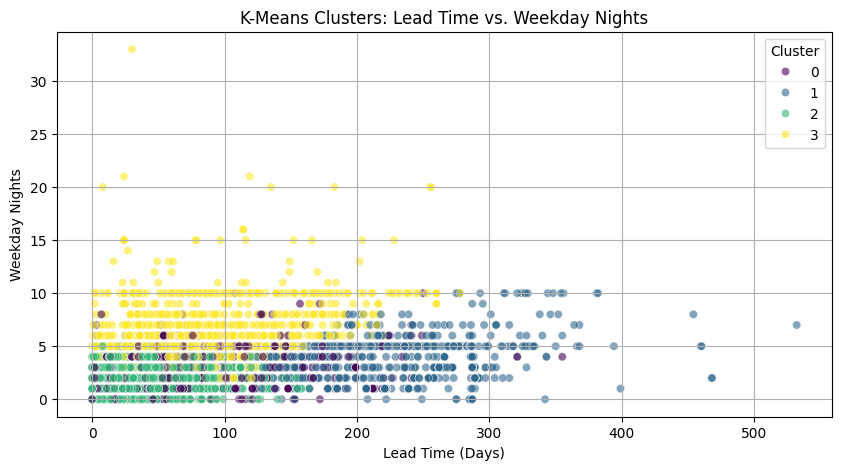

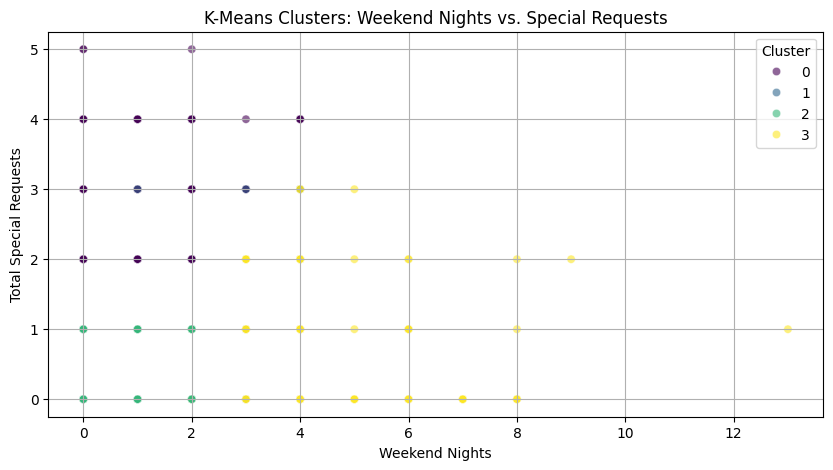

--- K-Means Cluster Feature Means Summary ---


,lead_time,stays_in_weekend_nights,stays_in_week_nights,total_of_special_requests
kmeans_cluster,,,,
0,59.511765,1.074790,2.964706,2.257143
1,229.020885,1.449631,3.882064,0.398034
2,22.353270,0.507443,1.657895,0.344498
3,79.659465,2.415123,5.829218,0.516975


In [7]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Define the features to use (using all the scaled features in scaled_df)
X = scaled_df

# Fit KMeans model with k=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init='auto')
clean_df['kmeans_cluster'] = kmeans.fit_predict(X)

# Visualization 1: Lead Time vs. Weekday Nights
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=clean_df,
    x='lead_time',
    y='stays_in_week_nights',
    hue='kmeans_cluster',
    palette='viridis',
    alpha=0.6
)
plt.title('K-Means Clusters: Lead Time vs. Weekday Nights')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Weekday Nights')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

# Visualization 2: Weekend Nights vs. Special Requests
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=clean_df,
    x='stays_in_weekend_nights',
    y='total_of_special_requests',
    hue='kmeans_cluster',
    palette='viridis',
    alpha=0.6
)
plt.title('K-Means Clusters: Weekend Nights vs. Special Requests')
plt.xlabel('Weekend Nights')
plt.ylabel('Total Special Requests')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

# Create summary table showing the averages for each behavior variable, broken out by cluster
summary_table = clean_df.groupby('kmeans_cluster')[selected_features].mean()
print("--- K-Means Cluster Feature Means Summary ---")
display(summary_table)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. What k value did you choose, and how did you decide?

I chose k = 4 as a starting point to separate customers into a manageable number of groups. This lets me compare different booking behaviors, including shorter stays, longer stays, and how far in advance guests book. Evaluation scores will help determine whether four clusters is a good fit.

2. What types of customers appear in each cluster, and which variables stand out?

Cluster 0 — Short stays with weekend nights: These guests book about 35 days ahead and stay around 1 weekend night and 0.85 weekday nights. They average 0.90 special requests. Short stays and relatively short booking lead times stand out most.

Cluster 1 — Longer stays booked early: These guests have the longest stays, averaging 3.5 weekend nights and 9.2 weekday nights. They also book the furthest ahead, at about 128 days. Stay length and lead time are the main features of this group.

Cluster 2 — Medium-length stays booked ahead: These guests average 1.7 weekend nights and 4.7 weekday nights, booking about 99 days in advance. Their stays are longer than those in Clusters 0 and 3 but shorter than those in Cluster 1.

Cluster 3 — Short weekday stays with few requests: These guests stay about 2 weekday nights and almost no weekend nights. They book around 36 days ahead and average just 0.39 special requests. Mostly weekday stays and few special requests distinguish this group.

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Soft clusters predicted successfully! Showing sample probabilities:
Row 0 probabilities: ['0.000', '1.000', '0.000', '0.000'] -> Chosen Cluster: 1
Row 1 probabilities: ['0.011', '0.003', '0.549', '0.437'] -> Chosen Cluster: 2
Row 2 probabilities: ['0.024', '0.006', '0.000', '0.969'] -> Chosen Cluster: 3
Row 3 probabilities: ['0.208', '0.003', '0.000', '0.789'] -> Chosen Cluster: 3
Row 4 probabilities: ['0.002', '0.000', '0.935', '0.063'] -> Chosen Cluster: 2


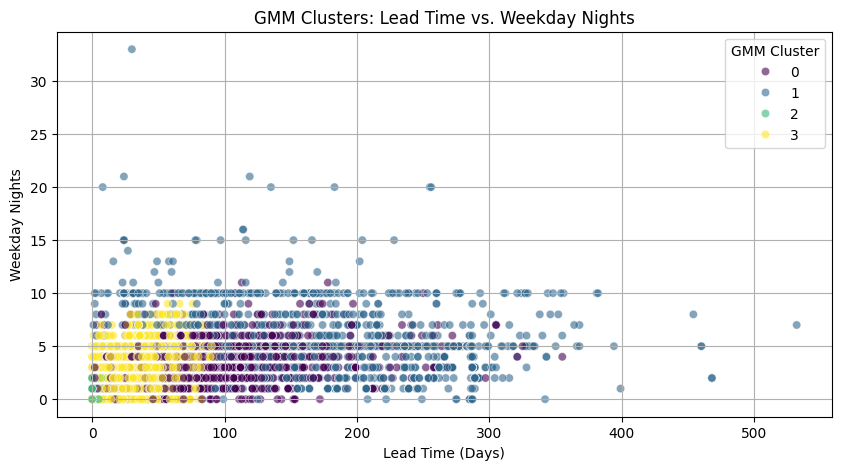

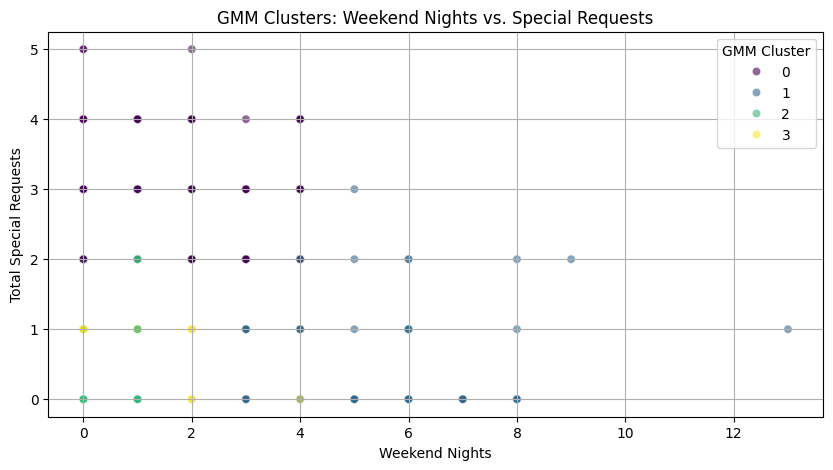


--- GMM Cluster Feature Means Summary ---


,lead_time,stays_in_weekend_nights,stays_in_week_nights,total_of_special_requests
gmm_cluster,,,,
0,86.558115,1.327225,3.570681,1.736649
1,181.199844,2.172628,5.545101,0.272939
2,1.515539,0.241316,0.953687,0.410116
3,33.190741,1.161852,3.042464,0.337626


In [8]:
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Fit Gaussian Mixture Model with 4 components (same as chosen in Part 3)
gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(scaled_df)

# 2. Predict soft clusters (probabilities)
# Each row will have an array of 4 probabilities summing to 1
soft_probs = gmm.predict_proba(scaled_df)

# To assign hard labels for visualization and summary calculations
clean_df['gmm_cluster'] = gmm.predict(scaled_df)

# Add probability of the assigned cluster to clean_df for reference
clean_df['gmm_prob'] = soft_probs.max(axis=1)

print("Soft clusters predicted successfully! Showing sample probabilities:")
for i in range(5):
    print(f"Row {i} probabilities: {['{:.3f}'.format(p) for p in soft_probs[i]]} -> Chosen Cluster: {clean_df['gmm_cluster'].iloc[i]}")

# 3. Visualization 1: Lead Time vs. Weekday Nights
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=clean_df,
    x='lead_time',
    y='stays_in_week_nights',
    hue='gmm_cluster',
    palette='viridis',
    alpha=0.6
)
plt.title('GMM Clusters: Lead Time vs. Weekday Nights')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Weekday Nights')
plt.legend(title='GMM Cluster')
plt.grid(True)
plt.show()

# 4. Visualization 2: Weekend Nights vs. Special Requests
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=clean_df,
    x='stays_in_weekend_nights',
    y='total_of_special_requests',
    hue='gmm_cluster',
    palette='viridis',
    alpha=0.6
)
plt.title('GMM Clusters: Weekend Nights vs. Special Requests')
plt.xlabel('Weekend Nights')
plt.ylabel('Total Special Requests')
plt.legend(title='GMM Cluster')
plt.grid(True)
plt.show()

# 5. Create summary table showing the averages for each behavior variable, broken out by GMM cluster
gmm_summary_table = clean_df.groupby('gmm_cluster')[selected_features].mean()
print("\n--- GMM Cluster Feature Means Summary ---")
display(gmm_summary_table)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
 1. GMM separated some booking patterns more clearly. For example, Cluster 2 captured last-minute, single-day stays, with an average lead time of about 1.5 days. Unlike KMeans, GMM also showed the probability of each booking belonging to each cluster. Row 1 had about a 55% probability of belonging to Cluster 2 and 44% for Cluster 3, suggesting its behavior falls between the two groups.

2. GMM could help the hotel identify guests whose booking habits fit more than one segment. For example, which guests fall between last-minute bookers and guests who plan ahead? How strongly does a booking fit a particular group? These probabilities could help the hotel tailor promotions more flexibly instead of treating every guest in a segment exactly the same.

## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [10]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

# Prepare evaluation data and cluster labels
X_eval = scaled_df
kmeans_labels = clean_df['kmeans_cluster']
gmm_labels = clean_df['gmm_cluster']

# Calculate KMeans metrics
kmeans_wcss = kmeans.inertia_
kmeans_silhouette = silhouette_score(X_eval, kmeans_labels)
kmeans_db = davies_bouldin_score(X_eval, kmeans_labels)

# Calculate GMM squared distances to component centers
gmm_centroids = gmm.means_
gmm_wcss = 0

for i in range(gmm.n_components):
    cluster_points = X_eval[gmm_labels == i]

    if len(cluster_points) > 0:
        gmm_wcss += np.sum((cluster_points - gmm_centroids[i]) ** 2).sum()

gmm_silhouette = silhouette_score(X_eval, gmm_labels)
gmm_db = davies_bouldin_score(X_eval, gmm_labels)

# Compare model metrics
print("=== CLUSTERING MODEL EVALUATION METRICS ===\n")
print(f"{'Metric':<32} | {'K-Means':<12} | {'GMM':<12}")
print("-" * 64)
print(
    f"{'WCSS (Lower is better)':<32} | "
    f"{kmeans_wcss:<12.3f} | {gmm_wcss:<12.3f}"
)
print(
    f"{'Silhouette (Higher is better)':<32} | "
    f"{kmeans_silhouette:<12.4f} | {gmm_silhouette:<12.4f}"
)
print(
    f"{'Davies-Bouldin (Lower is better)':<32} | "
    f"{kmeans_db:<12.4f} | {gmm_db:<12.4f}"
)

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


=== CLUSTERING MODEL EVALUATION METRICS ===

Metric                           | K-Means      | GMM         
----------------------------------------------------------------
WCSS (Lower is better)           | 13437.190    | 17494.855   
Silhouette (Higher is better)    | 0.3664       | 0.1426      
Davies-Bouldin (Lower is better) | 1.1103       | 1.5377      


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans performed better on all three metrics. Its WCSS was lower (13,437.190 vs. 17,494.855), and its silhouette score was higher (0.3664 vs. 0.1426). It also had a lower Davies-Bouldin Index (1.1103 vs. 1.5377). Overall, these results suggest KMeans produced tighter, better-separated clusters for this dataset.

5.3. I would recommend KMeans for this dataset because it performed better on the metrics and provides straightforward groups that are easy to explain. A business analyst could use these groups to develop targeted promotions for different booking behaviors. GMM would still be useful if the hotel wanted to understand guests who share characteristics across multiple segments.

## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [12]:
# Average cluster characteristics, sorted by lead time
kmeans_characteristics_sorted = (
    clean_df.groupby('kmeans_cluster')[selected_features]
    .mean()
    .sort_values('lead_time')
)

gmm_characteristics_sorted = (
    clean_df.groupby('gmm_cluster')[selected_features]
    .mean()
    .sort_values('lead_time')
)

print("KMeans Cluster Characteristics:")
display(kmeans_characteristics_sorted)

print("GMM Cluster Characteristics:")
display(gmm_characteristics_sorted)

KMeans Cluster Characteristics:


,lead_time,stays_in_weekend_nights,stays_in_week_nights,total_of_special_requests
kmeans_cluster,,,,
2,22.353270,0.507443,1.657895,0.344498
0,59.511765,1.074790,2.964706,2.257143
3,79.659465,2.415123,5.829218,0.516975
1,229.020885,1.449631,3.882064,0.398034


GMM Cluster Characteristics:


,lead_time,stays_in_weekend_nights,stays_in_week_nights,total_of_special_requests
gmm_cluster,,,,
2,1.515539,0.241316,0.953687,0.410116
3,33.190741,1.161852,3.042464,0.337626
0,86.558115,1.327225,3.570681,1.736649
1,181.199844,2.172628,5.545101,0.272939


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1.
- Last-minute guests: These guests book close to arrival, stay around 1–2 nights, and make few special requests.
- Guests with more special requests: These guests book about 60–86 days ahead and average roughly 1.7–2.2 special requests. Their bookings suggest they may value more personalized service.
- Longer-stay guests: These guests stay around 5–8 nights, including both weekdays and weekends.
- Early planners: These guests book about 181–229 days in advance and make relatively few special requests.

These patterns describe booking behavior, but they do not confirm whether guests are traveling for business, vacation, or family reasons.

2.
- Last-minute guests: Offer last-minute deals, simple mobile booking, and quick check-in.

- Guests with more special requests: Send pre-arrival messages to confirm their preferences and help arrange accommodations.

- Longer-stay guests: Offer extended-stay discounts, dining packages, or laundry services.

- Early planners: Offer early-booking discounts and optional packages they can arrange ahead of their stay.

## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The hardest part was knowing whether the clusters were useful because there were no correct labels to compare them against. I had to consider both the evaluation scores and whether the groups made sense from a business perspective. Choosing the number of clusters also required some judgment.

2. I would use clustering when I want to discover groups in data without having predefined labels. For example, a hotel could group guests by booking behavior without already knowing what customer segments exist.

3. Clustering helps us understand different types of guests instead of treating everyone the same. It can identify guests who book last minute, plan far ahead, or stay longer. The hotel can then use those patterns to create more relevant promotions and prepare services that fit each group’s needs.

4. This assignment helped me practice using data analysis to support business decisions. I prepared the data, applied KMeans and GMM, compared their results, and connected the customer segments to ideas the hotel could use.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [13]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 802007 bytes to assignment_09_clustering.html
